<a href="https://colab.research.google.com/github/Vishal-Srikanth/Lets-Land-This_Deep-Q-Learning-Lunar-Lander/blob/main/LetsLandThis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Q-Learning Lunar Lander: From Zero to Autonomous Landing

Welcome to this end-to-end reinforcement learning project! In this notebook, we build, train, and evaluate a **Deep Q-Network (DQN)** agent to solve the Gymnasium `LunarLander-v3` environment from scratch.

### Key Highlights:
* **Disk-Based Checkpointing Architecture:** Saves model weights directly to disk (`model_checkpoints/`) instead of accumulating tensors in RAM, entirely eliminating Google Colab memory crashes.

* **Multi-Milestone Video Showcase:** Automatically extracts checkpoints to render progression videos across training quartiles (0%, 25%, 50%, 75%, and 100%).

* **Trajectory Evolution Animation & Gallery:** Traces $(x, y)$ coordinates and landing orientations across training epochs into an animated GIF and a dynamic side-by-side visual gallery.

In [21]:
pip install gymnasium

In [22]:
import gymnasium as gym

## The Environment: Gymnasium & The Lunar Lander Challenge

### What is Gymnasium?
[Gymnasium](https://gymnasium.farama.org/) is the industry-standard toolkit developed by the Farama Foundation for developing and comparing reinforcement learning algorithms. It provides standardized environments (like Atari, physics simulations, and robotics) where an **agent** interacts with an **environment** through **states**, **actions**, and **rewards**.

### Problem Statement: LunarLander-v3
The objective of `LunarLander-v3` is to safely guide a lunar landing craft onto a designated landing pad marked between coordinates $x = -0.2$ and $x = 0.2$ at $(0,0)$.

* **State Space (8 Continuous Variables):**
  * $(x, y)$ coordinates (horizontal position and altitude)
  * $(v_x, v_y)$ linear velocities
  * $\theta$ (lander angle/orientation)
  * $\omega$ (angular velocity)
  * Two boolean flags indicating left and right leg ground contact.

* **Action Space (4 Discrete Actions):**
  * `0`: Do nothing
  * `1`: Fire left orientation engine
  * `2`: Fire main engine (vertical thrust)
  * `3`: Fire right orientation engine
  
* **Reward Structure:** Moving closer to the pad yields positive rewards, while crashing or using excessive fuel incurs heavy penalties. A successful landing yields around +200 to +300 points.

In [23]:
pip install swig

In [24]:
pip install "gymnasium[box2d]"

In [25]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torch.autograd as autograd
from torch.autograd import Variable
from collections import deque, namedtuple

Setting up the environment.

In [26]:
env = gym.make("LunarLander-v3")

Setting up the state.

In [27]:
state = env.observation_space.shape
state_size = env.observation_space.shape[0]
action_size = env.action_space.n
print(state)
print(state_size)
print(action_size)

(8,)
8
4


## Hyperparameter Configuration

Reinforcement learning stability heavily relies on tuning training dynamics. Below is the breakdown of our configuration:

| Hyperparameter | Value | Description |
| :--- | :--- | :--- |
| `learning_rate` | $5 \times 10^{-4}$ | Step size for the Adam optimizer when updating neural network weights. |
| `minibatch` | $150$ | Number of past experiences sampled randomly from memory for each training step. |
| `gamma` ($\gamma$) | $0.99$ | Discount factor determining the importance of future rewards vs. immediate rewards. |
| `replay_buffer_size` | $100,000$ | Maximum capacity of the experience replay memory buffer. |
| `interpolation_parameter` ($\tau$) | $0.001$ | Soft update rate controlling how fast target network weights blend with local weights. |
| `number_episodes` | $5,000$ | Hard safety limit on total training episodes. |
| `max_time_steps` | $1,000$ | Maximum physics steps allowed per episode before forced termination. |
| `epsilon` ($\epsilon$) | $1.0 \to 0.01$ | Exploration rate starting at 100% and decaying by $0.995$ per episode. |

In [28]:
learning_rate= 5e-4
minibatch = 150
gamma = 0.99
replay_buffer_size = 100000
interpolation_parameter = 1e-3
number_episodes = 5000
max_time_steps = 1000
epsilon_starting_value = 1.0
epsilon_ending_value = 0.01
epsilon_decay_value = 0.995
scores_100_episodes = deque(maxlen=100)

## Deep Q-Learning Architecture & Statistical Concepts

To master the environment, our agent combines Deep Neural Networks with Reinforcement Learning principles:

### 1. Artificial Neural Network (ANN)
Our Q-Network maps raw 8-dimensional states to expected future rewards (Q-values) for each of the 4 actions. It utilizes a 3-layer architecture:
* **Input Layer:** 8 neurons matching the state observation shape.
* **Hidden Layers:** Two fully connected layers with **ReLU (Rectified Linear Unit)** activation functions ($f(x) = \max(0, x)$) containing 64 neurons each to capture non-linear physics dynamics.
* **Output Layer:** 4 neurons outputting continuous Q-values for actions `[0, 1, 2, 3]`.

### 2. Experience Replay & Memory
Reinforcement learning data is highly correlated sequentially. The `ReplayMemory` class stores agent experiences $(s, a, r, s', \text{done})$ and samples random minibatches ($N=150$) to break temporal correlations and stabilize gradient descent.

### 3. Target Networks & Soft Updates
To prevent training oscillations caused by moving targets, we maintain two networks:
* **Local Network ($Q_{local}$):** Actively updated on every training step.
* **Target Network ($Q_{target}$):** Computes stable baseline Q-values and updates slowly via soft interpolation ($\tau = 0.001$).

### 4. The Bellman Equation & Target Calculation
The agent learns by minimizing Mean Squared Error (MSE) loss between predicted Q-values and target Q-values derived from the Bellman Optimality Equation:
$$Q_{target}(s, a) = r + \gamma \max_{a'} Q_{target}(s', a')$$

**Step-by-Step Intuition:**
1. At current state $s$, the agent takes action $a$.
2. It receives an immediate reward $r$.
3. The environment transitions to the new state $s'$.
4. In state $s'$, the agent evaluates all possible actions to find the maximum expected future Q-value.
5. This future value is discounted by $\gamma$ ($0.99$) and added to the immediate reward to form the target Q-value.

In [29]:
class ANN(nn.Module):
  def __init__(self, state_size, action_size, seed=42):
    super(ANN, self).__init__()
    self.seed = torch.manual_seed(seed)
    self.fc1 = nn.Linear(state_size, 64) #input layer with 64 neurons
    self.fc2 = nn.Linear(64, 64) #hidden layer
    self.fc3 = nn.Linear(64, action_size) #output layer

#next, the forward pass
  def forward(self, state):
    x = self.fc1(state) #pass through first layer
    x = F.relu(x) #apply relu activation function
    x = self.fc2(x) #pass through second layer
    x = F.relu(x) #apply relu activation function again
    return self.fc3(x) #pass out to output layer


## ReplayMemory class.

*ReplayMemory class* is designed to manage the agent's memory of game experiences. It stores state, action, reward, nect state and if the episode has ended for each step in the game.

In [30]:
class ReplayMemory(object):

  def __init__(self, capacity):
    self.capacity = capacity
    self.memory = []


  def push(self, event):
    self.memory.append(event)
    if len(self.memory) > self.capacity:
      del self.memory[0]

    #sample function takes random expereinces from the memory for the agent to train
    #here, batch size is number of experiences,
    #if batch size is 100, then the agent will pick 100 random experiences
    #from memory to train
  def sample(self, batch_size):
    experiences = random.sample(self.memory, batch_size)
    #next, converting these experiences into Pytorch Tensors
    states = torch.from_numpy(np.vstack([e[0] for e in experiences if e is not None])).float()
    actions = torch.from_numpy(np.vstack([e[1] for e in experiences if e is not None])).long()
    rewards = torch.from_numpy(np.vstack([e[2] for e in experiences if e is not None])).float()
    next_states = torch.from_numpy(np.vstack([e[3] for e in experiences if e is not None])).float()
    dones = torch.from_numpy(np.vstack([e[4] for e in experiences if e is not None]).astype(np.uint8)).float()
    return (states, actions, rewards, next_states, dones)


Agent Class

In [31]:
class Agent():
  def __init__(self, state_size, action_size):
    self.state_size = state_size
    self.action_size = action_size
    self.qnetwork_local = ANN(state_size, action_size)
    self.qnetwork_target = ANN(state_size, action_size)
    self.optimizer = optim.Adam(self.qnetwork_local.parameters(), lr=learning_rate)
    self.memory = ReplayMemory(replay_buffer_size)
    self.training_step = 0

  #making a step function that the agent calls on after every action
  def step(self, state, action, reward, next_state, done):
    self.memory.push((state, action, reward, next_state, done))
    self.training_step = (self.training_step + 1) % 4
    if self.training_step == 0:
      if len(self.memory.memory) > minibatch: #there should be atleast 150 experiences in the minibatch
        experiences = self.memory.sample(minibatch) #get random experiences from memory
        self.learn(experiences, gamma)

      #the get action function tell the agent what the next action should be
      #based on the current state.
      #it handles the exploration-exploitation tradeoff
  def get_action(self, state, epsilon):
    state = torch.from_numpy(state).float().unsqueeze(0)
    self.qnetwork_local.eval() #switched to evaluation mode to avoid unwanted updates
    with torch.no_grad(): #not calculating gradients for efficiency
      action_values = self.qnetwork_local(state)
    self.qnetwork_local.train() #switched back to training mode
    if random.random() > epsilon: #exploration-exploitation tradeoff
      return np.argmax(action_values.cpu().data.numpy()) #choosing the best predicted action, or action with the highest Q-value
    else:
      return random.choice(np.arange(self.action_size)) #exploration phase, agent chooses random move (0,1,2,3)

      #learn function for reinforcement learning training using Bellman Adaptation for Deep Q Learning
      # here, self.qnetwork_target(next_states) passes the batch of next states through the target Q-network to get
      # Q-vaues for all popssible actions the agent can take.
      # detach is used here to not update the weights during backpropogation
      #detach removes the computation graphs from the tensor, stopping gradients from flowing through it
      # .max(1)[0] find the maximum value for each next_state across all possible actions
      #The Bellman Equation selects the best possible future Q-value, assumming
      #the agent follows an optimal policy
      # .max(1) operates on dimension 1 and returns two values:
      # [0] = the maximum Q-value for each state
      # [1] = the index (action) corresponding to the max Q-value
      # but we dont need the index here, so we only ask for [0]=the max Q-value
      # .unsqueeze(1) adds a new dimension to the tensor
      # the expected sahpe of next_q_targets in (batch_size,1), but right now its (batch_size)
      # so .unsqueeze(1) makes it from an array to a column vector so it matches the other tensors
      # rewards and dones are column vectors, .unsqueeze(1) makes next state q-values have the same shape
      #
  def learn(self, experiences, gamma):
    states, actions, rewards, next_states, dones = experiences
    next_q_targets = self.qnetwork_target(next_states).detach().max(1)[0].unsqueeze(1)
    q_targets = rewards + (gamma * next_q_targets * (1 - dones)) #Bellman Equation
    q_expected = self.qnetwork_local(states).gather(1, actions) #only selects the Q-values from the action taken
    loss = F.mse_loss(q_expected, q_targets) #using MSE to compare loss between target and predicted Q-values
    self.optimizer.zero_grad() #resetting the gradient from previous steps to prevent accumulation
    loss.backward() #backpropgate the loss to the network
    self.optimizer.step() #updating the weights and adjusts the model paramenters using the computed gradients to minimize loss
    self.soft_update(self.qnetwork_local, self.qnetwork_target, interpolation_parameter)

      # qnetwork_local or local_model: the neural network that is actively learning
      # qnetwork_target or target_model: the stable neural network
      # interpolation_parameter (R): a factor between 0-1 that controls the update speed.
      #  if R=1: the target model immideiately copies the local model's weights (hard update)
      #  if R=0.01: the target model updates very slowly, blending only 1% of the local model's parameters at a time
      # Formula: TargetUpdateParam = (R)(LocalUpdateParam) + (1-R)(TargetUpdateParam)
      #
  def soft_update(self, qnetwork_local, qnetwork_target, interpolation_parameter):
    for target_param, local_param in zip(qnetwork_target.parameters(), qnetwork_local.parameters()):
      target_param.data.copy_(interpolation_parameter * local_param.data + (1.0 - interpolation_parameter) * target_param.data)



^ Building Local and Target networks

Local and Target networs are a desing choice in Deep Q-Learning (DQN) to improve the stability and convergence of training.

Local = *qnetwork_local*
- Actively updated during training
- Used to predict Q-values for the current state when the agent selects actions

Target = *qnetwork_target*
- Used to compute the target Q-values for the next during training
- Updated less frequently than the local Q-network to provide stable targets.

## Exploration - Exploitation Tradeoff

Exploration: The agent tries new actions to discover potentially better rewards or strategies.

Exploitation: The agent uses the knowledge it already has to maximize rewards by choosing the best-known action.

The tradeoff is important becuase:
- Exploration is necessary to ensure the agent doesnt miss out on better options or strategies that it hasn't tried yet.
- Exploitation ensures the agent leverages its current knowledge to achieve high rewards efficiently.

## Exploration-Exploitation & Success Criteria

### What is Epsilon ($\epsilon$)?
During early training, the agent knows nothing and must explore randomly. We use an **$\epsilon$-greedy policy**:
* With probability $\epsilon$, the agent chooses a completely random action (**Exploration**).
* With probability $1 - \epsilon$, it chooses the action with the highest predicted Q-value (**Exploitation**).
$\epsilon$ decays exponentially from `1.0` down to a floor of `0.01` (`epsilon = max(0.01, 0.995 * epsilon)`), allowing the agent to transition from curious explorer to master pilot.

### What Does the Score Mean & Why 200.0?
* **The Score:** The cumulative reward accumulated by the lander throughout an episode. Crashing results in a score around -100, while a gentle touchdown on the pad scores +200 or higher.

* **The Success Criterion ($\ge 200.0$ over 100 consecutive episodes):** Gymnasium defines `LunarLander-v3` as **officially solved** when the running average score of the last 100 episodes reaches or exceeds **200.0**. This statistically proves the agent has achieved consistent, reliable landing mastery rather than a lucky one-off success.

## Running the agent

In [34]:
import copy
import shutil

# Create a clean folder on disk for weight checkpoints (takes 0 RAM)
CHECKPOINT_DIR = "model_checkpoints"
if os.path.exists(CHECKPOINT_DIR):
    shutil.rmtree(CHECKPOINT_DIR)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# 1. Initialize the Agent
agent = Agent(state_size, action_size)

# Save initial weights for Episode 0 (Before training) to disk
torch.save(agent.qnetwork_local.state_dict(), f"{CHECKPOINT_DIR}/ep_0.pth")

# 2. Setup Training Parameters
number_episodes = 5000
epsilon = epsilon_starting_value
scores_100_episodes = deque(maxlen=100)
solved_episode = None
final_epsilon = epsilon

print(f"Starting training across episodes (up to {number_episodes} limit)...")

# 3. Main Training Loop
for episode in range(1, number_episodes + 1):
    state, _ = env.reset()
    score = 0

    for time_step in range(max_time_steps):
        action = agent.get_action(state, epsilon)
        next_state, reward, done, _, _ = env.step(action)
        agent.step(state, action, reward, next_state, done)
        state = next_state
        score += reward
        if done:
            break

    scores_100_episodes.append(score)
    mean_score = np.mean(scores_100_episodes)

    # Save a snapshot of the model weights to disk (frees RAM)
    torch.save(agent.qnetwork_local.state_dict(), f"{CHECKPOINT_DIR}/ep_{episode}.pth")


    # Epsilon decay
    epsilon = max(epsilon_ending_value, epsilon_decay_value * epsilon)

    # Print episode number and epsilon every 100 episodes
    if episode % 100 == 0:
        print(f"Episode {episode}\tAverage Score: {mean_score:.2f}\tEpsilon: {epsilon:.3f}")

    # Check for success condition (Score >= 200 over 100 episodes)
    if mean_score >= 200.0:
        solved_episode = episode
        final_epsilon = epsilon
        torch.save(agent.qnetwork_local.state_dict(), 'model.pth')
        break

# Handle edge case if it hits max episodes without solving
if solved_episode is None:
    solved_episode = number_episodes
    final_epsilon = epsilon

# Required Final Summary Output
print(f"\nTook {solved_episode} episodes to Land Successfully with an epsilon value of {final_epsilon:.3f}")

Starting training across episodes (up to 5000 limit)...
Episode 100	Average Score: -150.74	Epsilon: 0.606
Episode 200	Average Score: -88.53	Epsilon: 0.367
Episode 300	Average Score: -45.19	Epsilon: 0.222
Episode 400	Average Score: 12.42	Epsilon: 0.135
Episode 500	Average Score: 105.14	Epsilon: 0.082
Episode 600	Average Score: 143.72	Epsilon: 0.049

Took 689 episodes to Land Successfully with an epsilon value of 0.032


## Training Results & Visual Interpretations

We now evaluate our trained agent across multiple visual dimensions:
1. **Milestone Videos:** Captures behavioral evolution at 0%, 25%, 50%, 75%, and 100% training completion.

2. **Trajectory Evolution Animation (`.gif`):** Traces spatial descent paths and landing tilt angles across checkpoints.

3. **Side-by-Side Visual Gallery:** Renders all trajectory snapshots concurrently for immediate qualitative analysis.

## Step 1: Milestone Video Generation
To qualitatively evaluate how the agent's behavior changes over time, we load saved weights from disk across training quartiles (`0%`, `25%`, `50%`, `75%`, and `100% success`) and render high-resolution exploitation rollouts.

In [36]:
import glob
import io
import base64
import imageio
import gc
from IPython.display import HTML, display

def record_video_from_disk(agent, env_name, ep_num, filename):
    """Loads weights from disk for a specific episode and records a single exploitation episode."""
    path = f"{CHECKPOINT_DIR}/ep_{ep_num}.pth"
    agent.qnetwork_local.load_state_dict(torch.load(path))

    env = gym.make(env_name, render_mode='rgb_array')
    state, _ = env.reset()
    done = False
    frames = []

    while not done:
        frame = env.render()
        frames.append(frame)
        action = agent.get_action(state, epsilon=0.0)
        next_state, reward, done, _, _ = env.step(action)
        state = next_state

    env.close()
    imageio.mimsave(filename, frames, fps=30)
    print(f"[Video Saved Successfully]: {filename}")

    # Clean up frame buffers locally inside the function
    del frames
    gc.collect()

# Calculate exact quartile checkpoints based on the actual solved episode count
ep_25 = int(solved_episode * 0.25)
ep_50 = int(solved_episode * 0.50)
ep_75 = int(solved_episode * 0.75)
ep_100 = solved_episode

print(f"Generating 5 milestone videos from disk checkpoints (Total run: {solved_episode} episodes):")
print(f" • 0% (Before training): Episode 0")
print(f" • 25% Progress: Episode {ep_25}")
print(f" • 50% Progress: Episode {ep_50}")
print(f" • 75% Progress: Episode {ep_75}")
print(f" • 100% Success: Episode {ep_100}\n")

# Generate all 5 videos safely using disk storage
record_video_from_disk(agent, 'LunarLander-v3', 0, 'progress_00_before_training.mp4')
record_video_from_disk(agent, 'LunarLander-v3', ep_25, f'progress_25_percent_ep{ep_25}.mp4')
record_video_from_disk(agent, 'LunarLander-v3', ep_50, f'progress_50_percent_ep{ep_50}.mp4')
record_video_from_disk(agent, 'LunarLander-v3', ep_75, f'progress_75_percent_ep{ep_75}.mp4')
record_video_from_disk(agent, 'LunarLander-v3', ep_100, f'progress_100_success_ep{ep_100}.mp4')

print("\nAll 5 milestone videos generated, saved, and RAM kept clean!")

Generating 5 milestone videos from disk checkpoints (Total run: 689 episodes):
 • 0% (Before training): Episode 0
 • 25% Progress: Episode 172
 • 50% Progress: Episode 344
 • 75% Progress: Episode 516
 • 100% Success: Episode 689



[Video Saved Successfully]: progress_00_before_training.mp4


[Video Saved Successfully]: progress_25_percent_ep172.mp4


[Video Saved Successfully]: progress_50_percent_ep344.mp4


[Video Saved Successfully]: progress_75_percent_ep516.mp4


[Video Saved Successfully]: progress_100_success_ep689.mp4

All 5 milestone videos generated, saved, and RAM kept clean!


## Step 2: Trajectory Evolution & Animation
While videos show visual rendering, plotting the actual $(x, y)$ coordinates and landing tilt angles across checkpoints gives us a precise mathematical view of the lander's path. We simulate evaluation rollouts and compile them into an animated progression GIF.

In [41]:
import os
import shutil
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import gc

# 1. Create a directory for trajectory frames
TRAJECTORY_DIR = "trajectory_frames"
if os.path.exists(TRAJECTORY_DIR):
    shutil.rmtree(TRAJECTORY_DIR)
os.makedirs(TRAJECTORY_DIR, exist_ok=True)

print("Simulating evaluation paths...")

frame_filenames = []

# Using step_size = 50 (gives 15 frames for 689 episodes)
step_size = 50
checkpoint_episodes = list(range(0, solved_episode + 1, step_size))
if solved_episode not in checkpoint_episodes:
    checkpoint_episodes.append(solved_episode)

total_frames = len(checkpoint_episodes)

# Create environment ONCE outside the loop
env_eval = gym.make('LunarLander-v3')

for i, ep in enumerate(checkpoint_episodes):
    path_file = f"{CHECKPOINT_DIR}/ep_{ep}.pth"
    if not os.path.exists(path_file):
        continue

    print(f"Processing frame {i+1} of {total_frames} (Episode {ep}/{solved_episode})...")

    # Load weights for this episode
    agent.qnetwork_local.load_state_dict(torch.load(path_file))

    # Run evaluation rollout with a strict step limit safety guard
    state, _ = env_eval.reset()
    done = False
    step_count = 0
    max_eval_steps = 1000

    x_path = []
    y_path = []
    final_angle = 0.0

    while not done and step_count < max_eval_steps:
        x_path.append(state[0])
        y_path.append(state[1])
        final_angle = state[4]

        action = agent.get_action(state, epsilon=0.0)
        next_state, reward, done, _, _ = env_eval.step(action)
        state = next_state
        step_count += 1

    # Plot trajectory using explicit figure creation and cleanup
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.plot(x_path, y_path, color='dodgerblue', alpha=0.8, linewidth=1.5, label='Lander Path')
    ax.scatter(x_path[0], y_path[0], color='green', s=40, zorder=5, label='Start Position')

    # Draw landing pad boundaries
    ax.axvline(x=-0.2, color='gray', linestyle='--', alpha=0.6, label='Pad Flags')
    ax.axvline(x=0.2, color='gray', linestyle='--', alpha=0.6)
    ax.axhline(y=0, color='black', linewidth=1, alpha=0.5)

    # Draw orientation indicator at final point
    final_x, final_y = x_path[-1], y_path[-1]
    arrow_len = 0.15
    dx = arrow_len * np.sin(final_angle)
    dy = arrow_len * np.cos(final_angle)
    ax.arrow(final_x, final_y, dx, dy, color='crimson', head_width=0.05, zorder=6, label='Final Orientation')
    ax.scatter(final_x, final_y, color='crimson', s=50, zorder=6)

    # Graph styling
    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-0.2, 1.5)
    ax.set_title(f"Episode {ep} / {solved_episode}", fontsize=14, fontweight='bold')
    ax.set_xlabel("X Position", fontsize=10)
    ax.set_ylabel("Y Position (Altitude)", fontsize=10)
    ax.legend(loc='upper right', fontsize=8)
    ax.grid(True, linestyle=':', alpha=0.5)

    # Save frame image
    frame_path = f"{TRAJECTORY_DIR}/frame_ep_{ep:04d}.png"
    fig.savefig(frame_path, dpi=100, bbox_inches='tight')
    plt.close(fig)
    plt.close('all')

    frame_filenames.append(frame_path)
    gc.collect()

env_eval.close()
print(f"\nAll {len(frame_filenames)} frames generated instantly! Compiling animation...")


Simulating evaluation paths...
Processing frame 1 of 15 (Episode 0/689)...
Processing frame 2 of 15 (Episode 50/689)...
Processing frame 3 of 15 (Episode 100/689)...
Processing frame 4 of 15 (Episode 150/689)...
Processing frame 5 of 15 (Episode 200/689)...
Processing frame 6 of 15 (Episode 250/689)...
Processing frame 7 of 15 (Episode 300/689)...
Processing frame 8 of 15 (Episode 350/689)...
Processing frame 9 of 15 (Episode 400/689)...
Processing frame 10 of 15 (Episode 450/689)...
Processing frame 11 of 15 (Episode 500/689)...
Processing frame 12 of 15 (Episode 550/689)...
Processing frame 13 of 15 (Episode 600/689)...
Processing frame 14 of 15 (Episode 650/689)...
Processing frame 15 of 15 (Episode 689/689)...

All 15 frames generated instantly! Compiling animation...


/tmp/ipykernel_67155/1109519101.py:103: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = imageio.imread(filename)


Animation saved successfully as 'lunar_learning_trajectory.gif'!


In [51]:

# Stitch frames into an animated GIF
gif_filename = "lunar_learning_trajectory5.gif"
with imageio.get_writer(gif_filename, mode='I', duration=0.1) as writer:
    for filename in frame_filenames:
        image = imageio.imread(filename)
        for _ in range(3):
            writer.append_data(image)

print(f"Animation saved successfully as '{gif_filename}'!")

/tmp/ipykernel_67155/373380191.py:5: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = imageio.imread(filename)


Animation saved successfully as 'lunar_learning_trajectory5.gif'!


## Step 3: Side-by-Side Visual Gallery
To review the entire training progression at a single glance without clicking through individual files, we dynamically scan the saved frames directory and render them in a responsive, base64-embedded HTML gallery.

Displaying 15 trajectory evolution frames side-by-side:




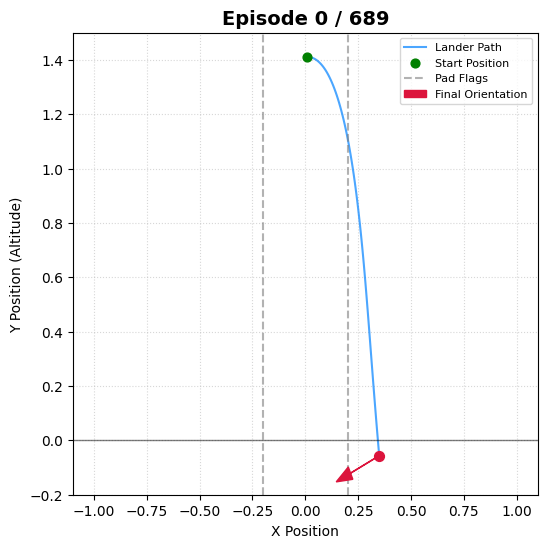
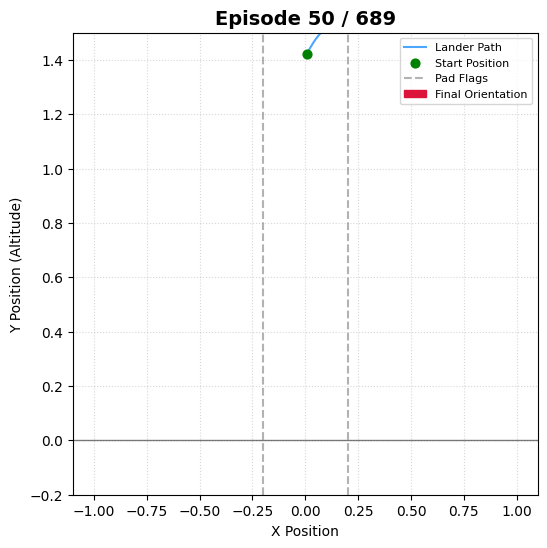
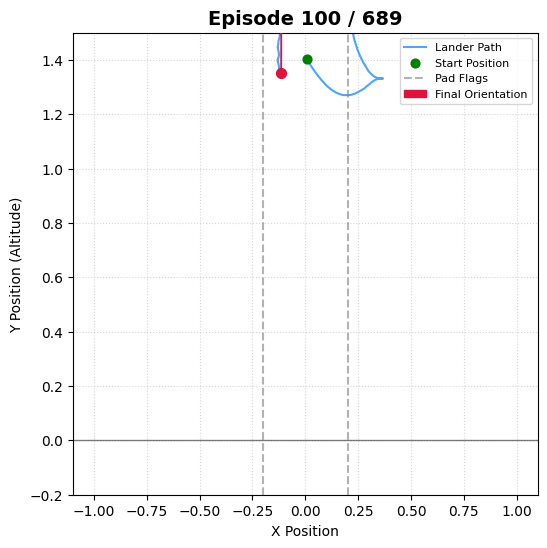
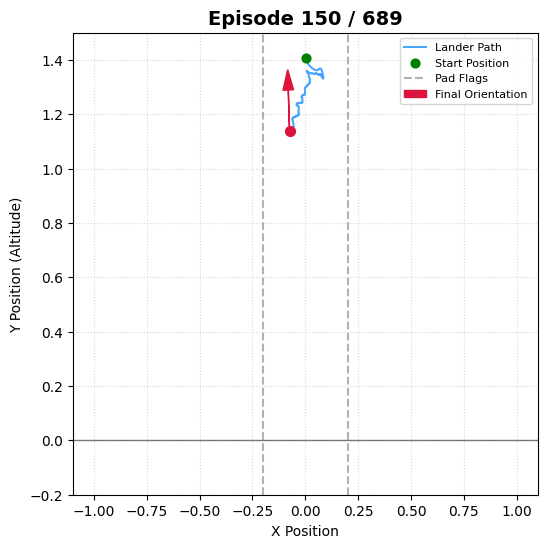
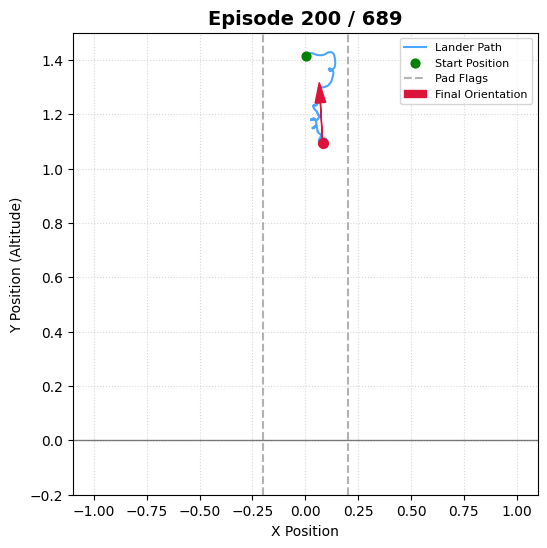
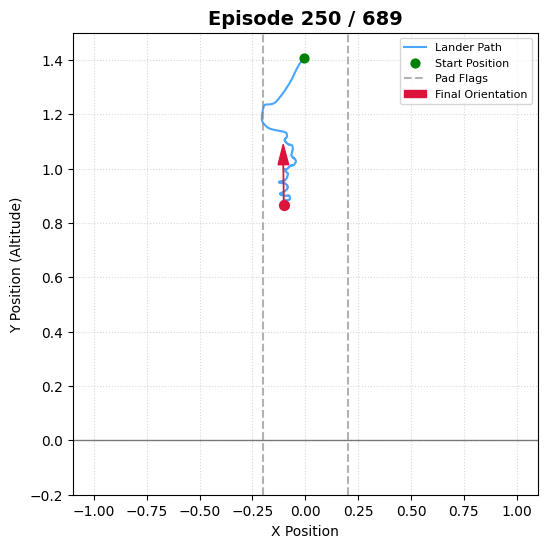
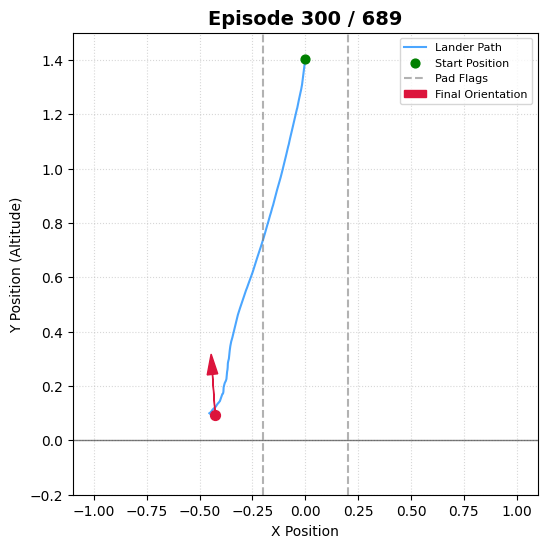
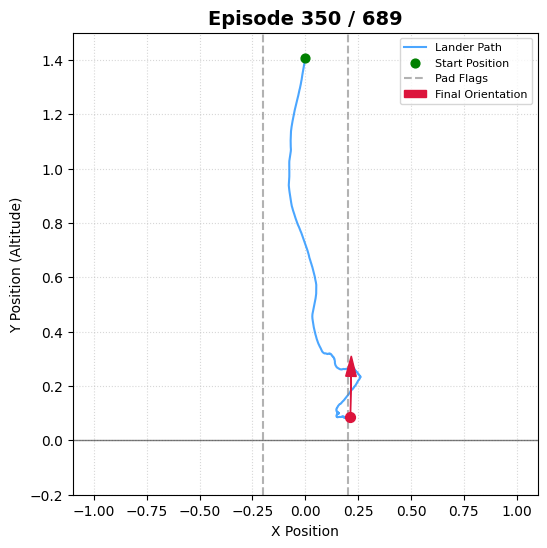
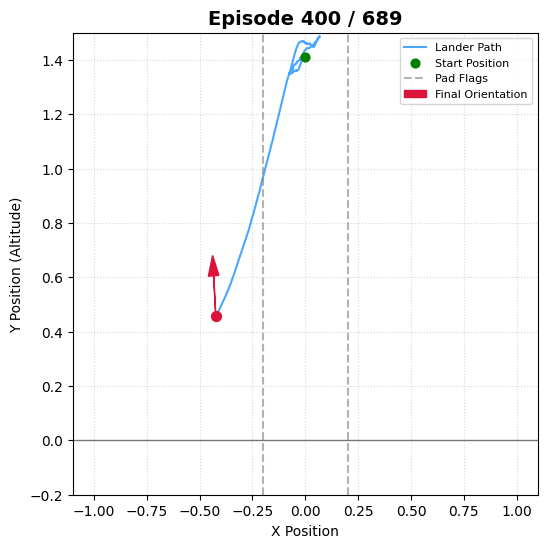
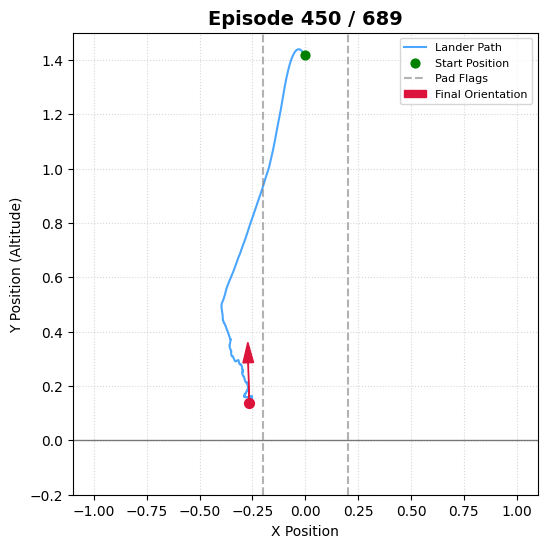
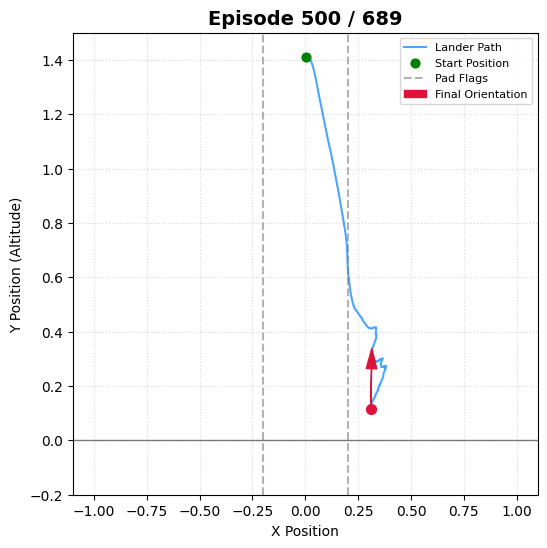
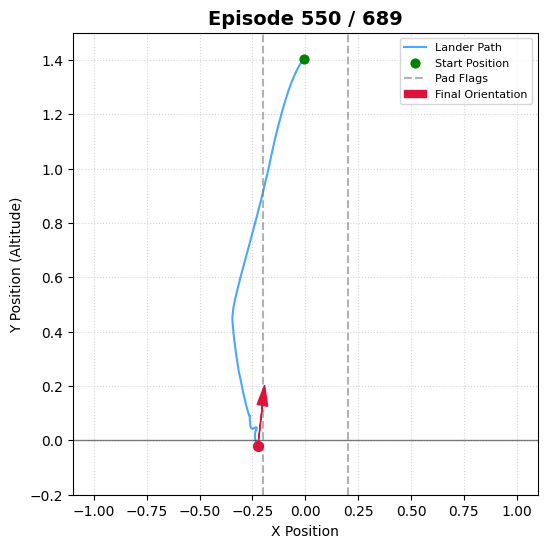
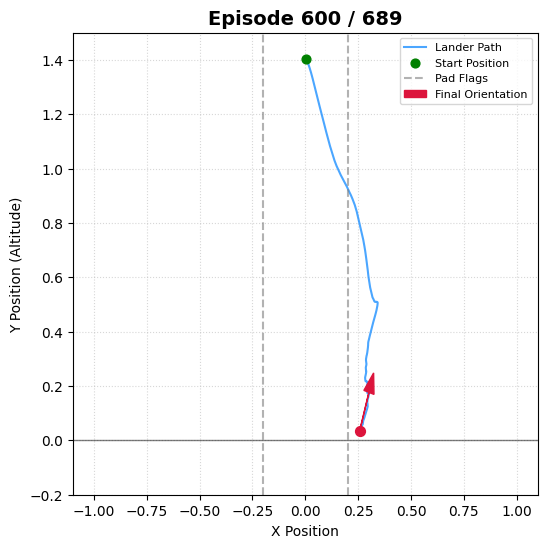
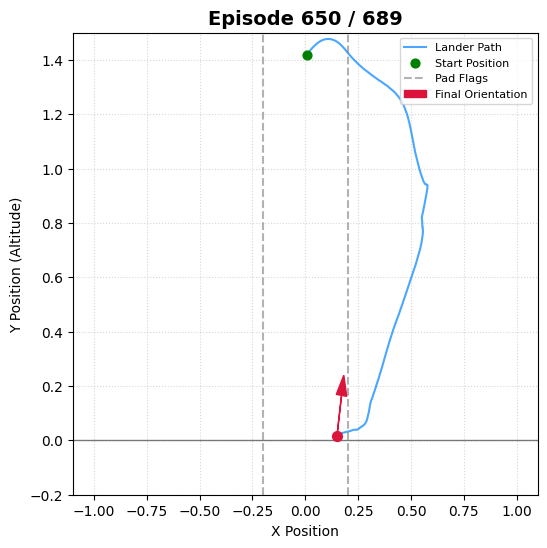
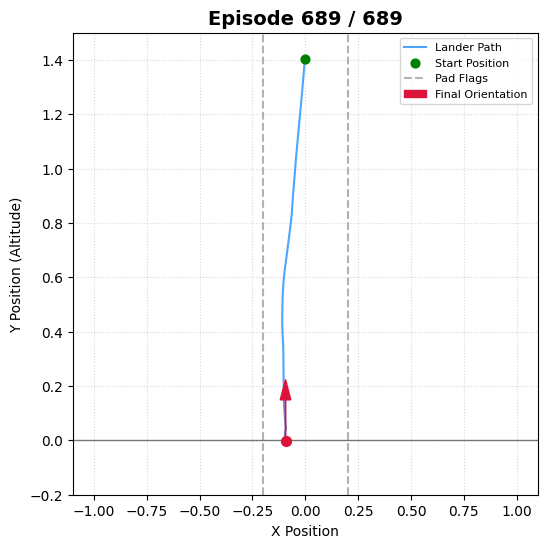

In [54]:
import glob
import os
import base64
from IPython.display import display, HTML

# Dynamically find and sort all PNG files in the trajectory directory
frames_dir = "trajectory_frames"
png_files = sorted(glob.glob(os.path.join(frames_dir, "*.png")))

if not png_files:
    print("No trajectory frames found in 'trajectory_frames/' directory!")
else:
    print(f"Displaying {len(png_files)} trajectory evolution frames side-by-side:\n")

    # Build a responsive HTML flexbox grid with embedded base64 image data
    html_content = '<div style="display: flex; flex-wrap: wrap; gap: 12px; justify-content: center;">'

    for file_path in png_files:
        filename = os.path.basename(file_path)

        # Read image and convert to base64 encoding so Colab renders it securely
        with open(file_path, "rb") as img_file:
            encoded_string = base64.b64encode(img_file.read()).decode('utf-8')

        html_content += f'''
        <div style="border: 1px solid #dcdcdc; padding: 8px; border-radius: 6px; background: #fafafa; text-align: center; box-shadow: 0 2px 4px rgba(0,0,0,0.05);">
            <img src="data:image/png;base64,{encoded_string}" style="width: 210px; height: auto; border-radius: 4px;" />
            <p style="font-size: 11px; font-weight: bold; margin: 6px 0 0 0; color: #444;">{filename}</p>
        </div>
        '''
    html_content += '</div>'

    display(HTML(html_content))

## Project Conclusion & Results Summary

Our Deep Q-Network successfully mastered the Gymnasium `LunarLander-v3` environment, achieving official solved status in **689 episodes** with a final exploration rate ($\epsilon$) of **0.032**.

### Key Takeaways:
* **Stability via Architecture:** By decoupling local and target networks through soft updates ($\tau = 0.001$) and utilizing experience replay, the agent avoided catastrophic forgetting and steadily climbed from negative rewards to consistent positive scoring ($\ge 200.0$).

* **Resource Efficiency:** Leveraging disk-based weight checkpointing successfully bypassed Google Colab's RAM limits, allowing clean scaling across thousands of training episodes.

* **Visual Verification:** Both the milestone videos and the trajectory progression gallery confirm that the agent evolved from random gravitational free-falls into a precise, controlled landing pilot.